# Part 2 - LLM agent with tool calling + LoRA
### Walgampaya H. K. B. (220675T) 
### Samaramanna M. A. (220551K)

EN4554 Assignment 1. This notebook runs everything for part 2: the agent loop, the baseline evaluation,
LoRA finetuning and the evaluation of the finetuned model. It's set up for a free Colab T4 (fp16) and takes
roughly 30-40 min end to end.

- **Model:** Qwen2.5-0.5B-Instruct (its chat template supports tools)
- **Tools:** `calculator`, `convert_units`, `get_weather`, `get_stock_price`, `get_events` (weather / stocks / calendar use made-up data)
- **Data:** generated from templates, 1000 train / 100 val / 100 test (test uses different phrasings)

In [1]:
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !git clone -q https://github.com/HimethW/EN4554---Deep-Learening-for-Vision---LLM-Agents-Tool-Calling-Assignment1-.git repo
    %cd repo
    !pip install -q -r requirements.txt

In [2]:
# on colab, checkpoints go to drive so a disconnect doesn't kill the run
SAVE_DIR = "outputs"
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    SAVE_DIR = "/content/drive/MyDrive/en4554_tool_calling"
os.makedirs(SAVE_DIR, exist_ok=True)

In [3]:
import json, gc
import torch
import pandas as pd
import matplotlib.pyplot as plt
from transformers import set_seed
from transformers.utils import logging as hf_logging

from tools import TOOL_SCHEMAS, run_tool
from agent import load_model, run_agent, SYSTEM_PROMPT, DETAILED_PROMPT
from evaluate import evaluate, load_jsonl, compare
import train

hf_logging.disable_progress_bar()  # widget progress bars don't render on github

SEED = 42
set_seed(SEED)
print(torch.cuda.get_device_name(0), f"{torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

NVIDIA GeForce RTX 4060 Laptop GPU 8.6 GB


## 1. Tools

In [4]:
for t in TOOL_SCHEMAS:
    f = t["function"]
    print(f"{f['name']}({', '.join(f['parameters']['properties'])}) - {f['description']}")
print()
print(run_tool("calculator", {"expression": "(12 + 7) * 3"}))
print(run_tool("convert_units", {"value": 10, "from_unit": "km", "to_unit": "mile"}))
print(run_tool("get_weather", {"city": "Colombo"}))
print(run_tool("get_stock_price", {"symbol": "NVDA"}))
print(run_tool("get_events", {"day": "friday"}))

calculator(expression) - Evaluate an arithmetic expression exactly. Supports + - * / ** % and parentheses.
convert_units(value, from_unit, to_unit) - Convert a value between units of length, mass, volume or temperature.
get_weather(city) - Get the current weather (temperature in celsius) for a city.
get_stock_price(symbol) - Get the latest stock price in USD for a ticker symbol.
get_events(day) - List the user's calendar events for a day of the week.

{'expression': '(12 + 7) * 3', 'result': 57}
{'value': 10, 'from_unit': 'km', 'to_unit': 'mile', 'result': 6.21}
{'city': 'Colombo', 'temperature_c': 31, 'condition': 'thunderstorms', 'humidity_pct': 88}
{'symbol': 'NVDA', 'company': 'Nvidia', 'price_usd': 131.25}
{'day': 'friday', 'events': [{'time': '15:00', 'title': 'Deep learning lecture'}, {'time': '20:00', 'title': 'Movie night'}]}


## 2. Data

In [5]:
!{sys.executable} make_data.py
train_rows, val_rows, test_rows = (load_jsonl(f"data/{s}.jsonl") for s in ["train", "val", "test"])
counts = pd.DataFrame({s: pd.Series([r["kind"] for r in rows]).value_counts()
                       for s, rows in [("train", train_rows), ("val", val_rows), ("test", test_rows)]})
counts.loc["total"] = counts.sum()
counts

train 1000 {'convert': 150, 'weather': 140, 'none': 200, 'stock': 120, 'parallel': 50, 'weather_convert': 45, 'calc': 150, 'stock_calc': 35, 'events': 110}
val 100 {'stock': 12, 'events': 11, 'convert': 15, 'none': 20, 'weather': 14, 'stock_calc': 4, 'parallel': 5, 'calc': 15, 'weather_convert': 4}
test 100 {'none': 20, 'calc': 14, 'weather': 14, 'parallel': 6, 'stock': 12, 'stock_calc': 4, 'convert': 14, 'events': 12, 'weather_convert': 4}


,train,val,test
calc,150,15,14
convert,150,15,14
events,110,11,12
none,200,20,20
parallel,50,5,6
stock,120,12,12
stock_calc,35,4,4
weather,140,14,14
weather_convert,45,4,4
total,1000,100,100


In [6]:
# a few test requests (phrasings are different from the train templates)
for r in test_rows[:8]:
    print(f"[{r['kind']}] {r['query']}")

[none] What does a stock exchange do?
[none] In which country are the pyramids of Giza?
[calc] 2336 plus 4167 plus 5730 equals what?
[weather] I'm flying to Tokyo tonight, what are the conditions like there?
[calc] A shop sells 43 packs of 675 pencils. How many pencils in total?
[parallel] Look up both NVDA and ORCL for me.
[calc] Quick math: 10191/11
[none] Who wrote the Harry Potter books?


## 3. The agent loop (untouched model)

In [7]:
def show(trace):
    print("USER:", trace["query"])
    for s in trace["steps"]:
        print("  MODEL:", s["output"].replace("\n", " "))
        for c in s["calls"]:
            print("  TOOL :", c["name"], c["arguments"], "->", c["result"])
    print("  FINAL:", trace["final"])
    print()

model, tok = load_model()
demo = ["What's the weather in Oslo?", "How much would 12 shares of NVDA cost?",
        "What is the capital of France?", "Convert 5 miles to km."]
for t in run_agent(model, tok, demo):
    show(t)

USER: What's the weather in Oslo?
  MODEL: <tool_call> {"name": "get_weather", "arguments": {"city": "Oslo"}} </tool_call>
  TOOL : get_weather {'city': 'Oslo'} -> {'city': 'Oslo', 'temperature_c': 2, 'condition': 'foggy', 'humidity_pct': 90}
  MODEL: The current weather in Oslo is foggy with a humidity of 90%. The temperature is 2 degrees Celsius.
  FINAL: The current weather in Oslo is foggy with a humidity of 90%. The temperature is 2 degrees Celsius.

USER: How much would 12 shares of NVDA cost?
  MODEL: <tool_call> {"name": "get_stock_price", "arguments": {"symbol": "NVDA"}} </tool_call>
  TOOL : get_stock_price {'symbol': 'NVDA'} -> {'symbol': 'NVDA', 'company': 'Nvidia', 'price_usd': 131.25}
  MODEL: The current price of 1 share of Nvidia is $131.25. Therefore, 12 shares would cost you approximately $158.50.
  FINAL: The current price of 1 share of Nvidia is $131.25. Therefore, 12 shares would cost you approximately $158.50.

USER: What is the capital of France?
  MODEL: <tool_c

## 4. Baseline evaluation

Same agent loop and test set for every model. Metrics:
- **call validity** - first model turn parses as a tool call in the expected `<tool_call>{json}</tool_call>` format (tool requests only)
- **call accuracy** - right tool(s) with right arguments (arguments are normalised, e.g. `km` = `kilometers`)
- **abstention** - answers directly without a tool when none is needed (no-tool requests only)
- **task success** - final answer is correct end to end (contains the right numbers / keywords)

I also run the base model with a more detailed system prompt, to see how far prompting alone gets.

In [8]:
base_m, base_s = evaluate(model, tok, test_rows, "baseline")
prompt_m, prompt_s = evaluate(model, tok, test_rows, "baseline_detailed_prompt", system=DETAILED_PROMPT)
del model; gc.collect(); torch.cuda.empty_cache()
pd.DataFrame({"baseline": base_m, "baseline + detailed prompt": prompt_m}).loc[
    ["call_validity", "call_accuracy", "abstention", "task_success"]]

,baseline,baseline + detailed prompt
call_validity,85.0,77.5
call_accuracy,67.5,57.5
abstention,75.0,80.0
task_success,67.0,62.0


## 5. LoRA finetuning

LoRA (r=16, alpha=32, dropout 0.05) on all attention and MLP projections. Loss is only on the assistant
turns (tool calls and final answers); system, user and tool-result tokens are masked with -100.
2 epochs, lr 2e-4 with cosine decay, effective batch 16, fp16.

In [9]:
mem = torch.cuda.get_device_properties(0).total_memory / 1e9
bs, accum = (2, 8) if mem > 12 else (1, 16)  # effective batch 16 either way, bs 1 fits an 8GB card
adapter, log = train.train(out_dir=f"{SAVE_DIR}/lora", epochs=2, lr=2e-4, rank=16, alpha=32,
                           batch_size=bs, grad_accum=accum, seed=SEED)
gc.collect(); torch.cuda.empty_cache()

trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497


train 1000 / val 100 examples, tokens per example: mean 612, max 706


{'loss': '0.5343', 'grad_norm': '1.616', 'learning_rate': '0.0001333', 'epoch': '0.08'}


{'loss': '0.3781', 'grad_norm': '1.405', 'learning_rate': '0.0001997', 'epoch': '0.16'}


{'loss': '0.2818', 'grad_norm': '0.8337', 'learning_rate': '0.0001978', 'epoch': '0.24'}


{'loss': '0.129', 'grad_norm': '0.744', 'learning_rate': '0.0001943', 'epoch': '0.32'}


... (20 outputs left out)

{'loss': '0.01159', 'grad_norm': '0.1039', 'learning_rate': '1.675e-06', 'epoch': '1.912'}


{'loss': '0.01681', 'grad_norm': '0.1405', 'learning_rate': '1.37e-07', 'epoch': '1.992'}


{'eval_loss': '0.02267', 'eval_runtime': '20.19', 'eval_samples_per_second': '4.953', 'eval_steps_per_second': '4.953', 'epoch': '2'}


{'train_runtime': '1045', 'train_samples_per_second': '1.914', 'train_steps_per_second': '0.121', 'train_loss': '0.07737', 'epoch': '2'}


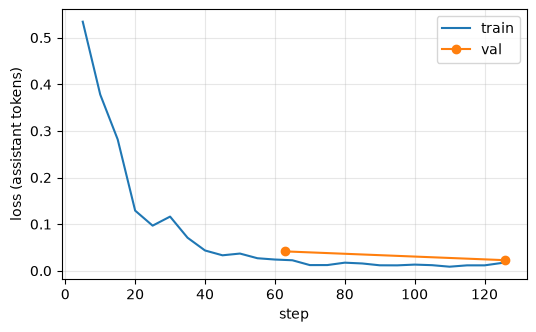

In [10]:
tr = [(x["step"], x["loss"]) for x in log if "loss" in x]
ev = [(x["step"], x["eval_loss"]) for x in log if "eval_loss" in x]
plt.figure(figsize=(6, 3.5))
plt.plot(*zip(*tr), label="train")
plt.plot(*zip(*ev), "o-", label="val")
plt.xlabel("step"); plt.ylabel("loss (assistant tokens)"); plt.legend(); plt.grid(alpha=.3)
os.makedirs("results", exist_ok=True)
plt.savefig("results/loss.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Evaluate the LoRA model

In [11]:
model, tok = load_model(adapter)
lora_m, lora_s = evaluate(model, tok, test_rows, "lora")
for t in run_agent(model, tok, demo):
    show(t)

USER: What's the weather in Oslo?
  MODEL: <tool_call> {"name": "get_weather", "arguments": {"city": "Oslo"}} </tool_call>
  TOOL : get_weather {'city': 'Oslo'} -> {'city': 'Oslo', 'temperature_c': 2, 'condition': 'foggy', 'humidity_pct': 90}
  MODEL: Right now Oslo is foggy at 2°C (humidity 90%).
  FINAL: Right now Oslo is foggy at 2°C (humidity 90%).

USER: How much would 12 shares of NVDA cost?
  MODEL: <tool_call> {"name": "get_stock_price", "arguments": {"symbol": "NVDA"}} </tool_call>
  TOOL : get_stock_price {'symbol': 'NVDA'} -> {'symbol': 'NVDA', 'company': 'Nvidia', 'price_usd': 131.25}
  MODEL: <tool_call> {"name": "calculator", "arguments": {"expression": "12 * 131.25"}} </tool_call>
  TOOL : calculator {'expression': '12 * 131.25'} -> {'expression': '12 * 131.25', 'result': 1575}
  MODEL: 12 shares of NVDA at $131.25 would cost $1575.
  FINAL: 12 shares of NVDA at $131.25 would cost $1575.

USER: What is the capital of France?
  MODEL: The capital of France is Paris.
  FIN

## 7. Results

In [12]:
rows = ["call_validity", "call_accuracy", "abstention", "task_success", "task_success_tool", "task_success_no_tool",
        "fully_correct"]
table = pd.DataFrame({"baseline": base_m, "baseline + detailed prompt": prompt_m, "LoRA": lora_m}).loc[rows]
table.to_csv("results/summary.csv")
table

,baseline,baseline + detailed prompt,LoRA
call_validity,85.0,77.5,100.0
call_accuracy,67.5,57.5,86.2
abstention,75.0,80.0,95.0
task_success,67.0,62.0,91.0
task_success_tool,67.5,57.5,90.0
task_success_no_tool,65.0,80.0,95.0
fully_correct,66.0,58.0,88.0


In [13]:
pd.DataFrame({"baseline": base_m["per_kind_success"], "baseline + detailed prompt": prompt_m["per_kind_success"],
              "LoRA": lora_m["per_kind_success"]})

,baseline,baseline + detailed prompt,LoRA
calc,100.0,50.0,85.7
convert,92.9,85.7,100.0
events,66.7,66.7,100.0
none,60.0,65.0,95.0
parallel,33.3,33.3,50.0
stock,66.7,66.7,66.7
stock_calc,0.0,0.0,50.0
weather,64.3,57.1,100.0
weather_convert,0.0,0.0,100.0


## 8. Failure analysis

Every failed test case gets one category (first one that applies):
`no_call` (answered without calling a needed tool), `wrong_format` (tried to call but it doesn't parse),
`wrong_tool`, `wrong_argument`, `missing_call` (stopped before the 2nd call), `extra_call`,
`ignored_tool_result` (calls were right but the final answer is wrong), `no_final_answer` (hit the step limit),
`unnecessary_call` (called a tool for a no-tool request), `wrong_answer` (no-tool request answered wrongly).

In [14]:
pd.DataFrame({"baseline": base_m["failures"], "baseline + detailed prompt": prompt_m["failures"],
              "LoRA": lora_m["failures"]}).fillna(0).astype(int)

,baseline,baseline + detailed prompt,LoRA
wrong_answer,3,3,0
no_call,12,18,0
wrong_tool,3,5,3
unnecessary_call,5,4,1
missing_call,8,6,2
wrong_argument,3,5,6
ignored_tool_result,0,1,0


In [15]:
fixed, kept, introduced = compare(base_s, lora_s)
print("fixed by LoRA (baseline category):", dict(fixed))
print("still failing (baseline -> LoRA category):", dict(kept))
print("introduced by LoRA:", dict(introduced))

fixed by LoRA (baseline category): {'wrong_answer': 3, 'no_call': 9, 'wrong_tool': 3, 'unnecessary_call': 4, 'missing_call': 6}
still failing (baseline -> LoRA category): {('missing_call', 'missing_call'): 2, ('no_call', 'wrong_tool'): 3, ('wrong_argument', 'wrong_argument'): 3, ('unnecessary_call', 'unnecessary_call'): 1}
introduced by LoRA: {'wrong_argument': 3}


In [16]:
def failures(name, n=12):
    cases = load_jsonl(f"results/{name}_cases.jsonl")
    bad = [c for c in cases if not c["passed"]]
    print(f"== {name}: {len(bad)} failures, showing {min(n, len(bad))}\n")
    for c in bad[:n]:
        print(f"[{c['category']}] {c['query']}")
        for s in c["trace"]["steps"]:
            print("   ", s["output"][:220].replace("\n", " "))
            for call in s["calls"]:
                print("    ->", call["result"])
        print()

failures("baseline")

== baseline: 34 failures, showing 12

[wrong_answer] In which country are the pyramids of Giza?
    To provide you with the information about the location of the pyramids of Giza, I will use the 'get_weather' tool. Please provide me with the city where you want to check the weather.

[no_call] I'm flying to Tokyo tonight, what are the conditions like there?
    To provide you with the most accurate information about the current weather conditions in Tokyo, I'll need your location details. Could you please tell me your city or zip code so I can fetch the necessary data?

[wrong_tool] Look up both NVDA and ORCL for me.
    <tool_call> {"name": "get_weather", "arguments": {"city": "New York"}} </tool_call> <tool_call> {"name": "get_weather", "arguments": {"city": "Orlando"}} </tool_call>
    -> {'city': 'New York', 'temperature_c': 8, 'condition': 'windy', 'humidity_pct': 47}
    -> {'error': "no weather data for 'Orlando'"}
    The current temperature in New York is 8 degrees Celsius, wi

In [17]:
failures("lora")

== lora: 12 failures, showing 12

[missing_call] price for 250 x AMZN stock?
    <tool_call> {"name": "get_stock_price", "arguments": {"symbol": "AMZN"}} </tool_call>
    -> {'symbol': 'AMZN', 'company': 'Amazon', 'price_usd': 176.4}
    The latest price for AMZN is $176.40.

[wrong_tool] How much would one share of Intel cost me today?
    <tool_call> {"name": "get_stock_price", "arguments": {"symbol": "INTC"}} </tool_call>
    -> {'symbol': 'INTC', 'company': 'Intel', 'price_usd': 31.44}
    <tool_call> {"name": "calculator", "arguments": {"expression": "1 / 0.3144"}} </tool_call>
    -> {'expression': '1 / 0.3144', 'result': 3.18}
    One share of INTC at $31.44 would cost $3.18.

[wrong_argument] GOOGL and NKE share prices?
    <tool_call> {"name": "get_stock_price", "arguments": {"symbol": "GOOGL"}} </tool_call> <tool_call> {"name": "get_stock_price", "arguments": {"symbol": "NEK"}} </tool_call>
    -> {'symbol': 'GOOGL', 'company': 'Alphabet', 'price_usd': 151.86}
    -> {'error'

## Notes

- LoRA fixes the format completely (validity 100%) and learns *when* to call: no missed calls, abstention 75 -> 95%, and it can chain two calls (0/8 -> 6/8 two-step requests).
- The detailed prompt alone made the base model worse at calling tools (accuracy 67.5 -> 57.5), so prompting isn't enough at 0.5B.
- What's left are inputs that don't look like the training templates: unseen tickers (NKE -> "NEK"), company names only seen in test (Coca-Cola -> "COG"), "add a and b, then multiply by c", and "how much would one share of X cost" which LoRA confuses with the n-shares template.

Full discussion in `writeup.md`.